Calibration of motorized HWP
data0722.csv -- rot of Motor 1, H pol measurement, 1s per angle
data0722_2.csv -- repeated rot of Motor 1, H pol measurement, 1s per angle
data0722_0.3s.csv -- repeated rot of Motor 1, H pol measurement, 0.3s per angle, 0.05 resolution
data0730.csv -- rot of Motor 1, V pol measurement, 0.3s per angle, 0.05 resolution

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


# Columns:
# 0 = Time; 1 = Motor 2 angle; 2 = Motor 1 angle
# 3 = Wavelength; 4 = Power

[hwp_ang, power] = np.loadtxt(
    "data_1s_V.csv",
    delimiter=",",
    skiprows=1,
    #max_rows=4500,
    #usecols=(2, 4),
    unpack=True
)

#mask = (power0 < 0.0015) | (power0 > 0.007)
#hwp_ang = hwp_ang0[mask]
#power = power0[mask]

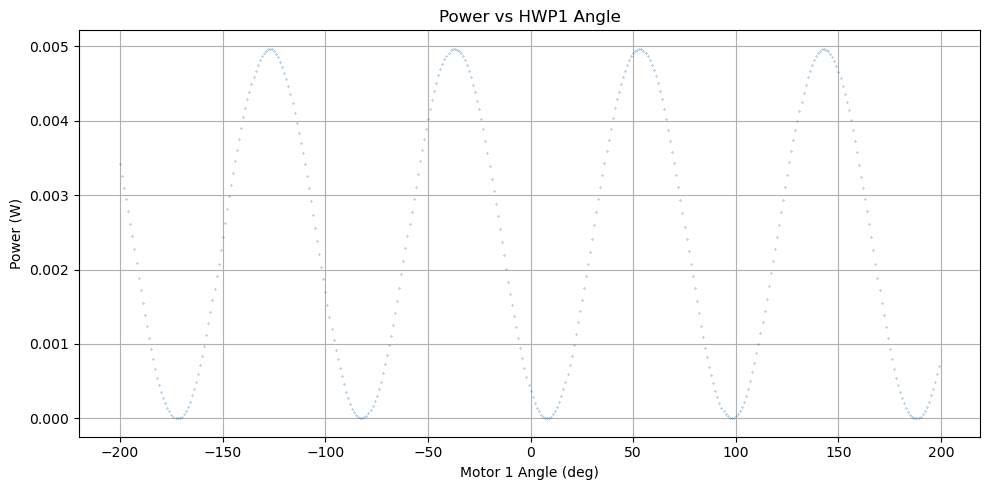

In [26]:
plt.figure(figsize=(10, 5))

plt.plot(hwp_ang, power, marker=".", markersize=0.5, linewidth=0)

plt.xlabel("Motor 1 Angle (deg)")
plt.ylabel("Power (W)")
plt.title("Power vs HWP1 Angle")
plt.grid(True)
plt.tight_layout()
plt.show()

In [27]:
# Fit function:
# P(theta) = p0 + p*cos^2[2*(theta - theta0)]
def power_function(theta, P0, P, theta0):
    phase = np.deg2rad(2 * (theta - theta0))
    return P0 + P * np.cos(phase)**2

# Initial guesses
P0_guess = 0
P_guess = np.max(power)
theta0_guess = hwp_ang[np.argmax(power)]

para_guess = [P0_guess, P_guess, theta0_guess]

# Perform fit
paras, covar = curve_fit(
    power_function,
    hwp_ang, power,
    p0=para_guess,
    #bounds=([0, -np.inf, -np.inf], [np.inf,  np.inf,  np.inf])# P0 >= 0
)

P0, P, theta0 = paras
errors = np.sqrt(np.diag(covar))

print("Fit parameters:", paras)
print("Parameter errors:", errors)

print(f"P0 = {P0*1e3:.8g} ± {errors[0]*1e3:.2g} mW")
print(f"P  = {P*1e3:.8g} ± {errors[1]*1e3:.2g} mW")
print(f"theta0 = {theta0:.6f} ± {errors[2]:.2g} deg")

Fit parameters: [ 9.19627341e-06  4.95978904e-03 -1.27107857e+02]
Parameter errors: [1.54349584e-06 2.62134777e-06 7.59204903e-03]
P0 = 0.0091962734 ± 0.0015 mW
P  = 4.959789 ± 0.0026 mW
theta0 = -127.107857 ± 0.0076 deg


In [32]:
print(f"max and min at = {theta0-90} {theta0-45} {theta0} {theta0+45} {theta0+90} {theta0+135} {theta0+180}deg")

max and min at = -217.10785728478768 -172.10785728478768 -127.10785728478768 -82.10785728478768 -37.107857284787684 7.892142715212316 52.892142715212316deg


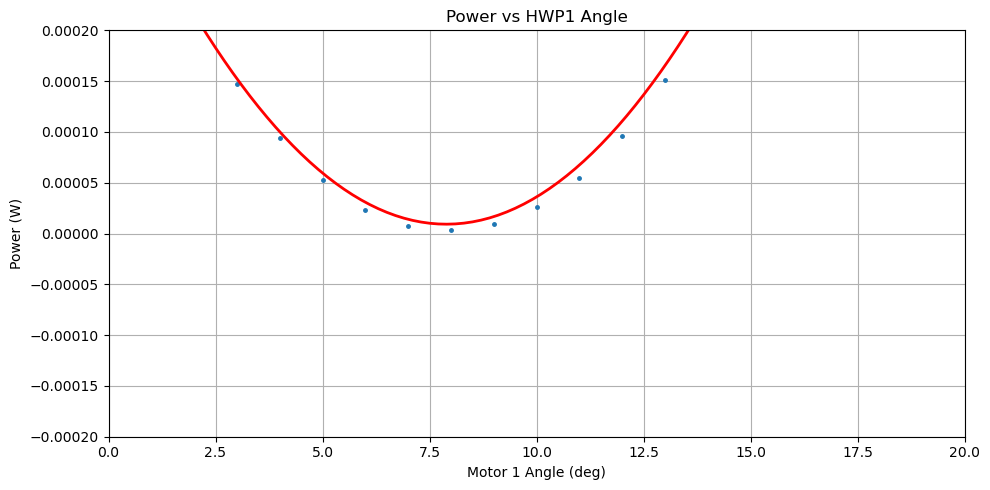

In [31]:
plt.figure(figsize=(10, 5))

hwpls = np.linspace(-200, 200, 2000)

plt.plot(hwp_ang, power, marker=".", markersize=5, linewidth=0)
plt.plot(hwpls, power_function(hwpls, *paras), color="red", label="Fit", linewidth=2)

plt.xlim([0, 20])
plt.ylim([-0.0002, 0.0002])
#plt.ylim([0.008, 0.009])
plt.xlabel("Motor 1 Angle (deg)")
plt.ylabel("Power (W)")
plt.title("Power vs HWP1 Angle")
plt.grid(True)
plt.tight_layout()
plt.show()

In [29]:
idx = np.argsort(power)

print("100 minimum:")
for i in idx[:20]:
    print(hwp_ang[i], power[i] * 1e3, "mW")

print("100 maximum:")
for i in idx[-20:][::-1]:
    print(hwp_ang[i], power[i] * 1e3, "mW")

100 minimum:
188.0 0.00294310212 mW
-172.0 0.0029574291600000004 mW
98.0 0.00297891961 mW
8.0 0.00301283626 mW
-82.0 0.00337174015 mW
-83.0 0.00609080917 mW
7.0 0.0070449673300000005 mW
187.0 0.00743570263 mW
-173.0 0.00750155823 mW
99.0 0.00817912678 mW
189.0 0.00904255285 mW
-171.0 0.0090586509 mW
9.0 0.009330849019999999 mW
97.0 0.0104650098 mW
-81.0 0.0132996793 mW
-84.0 0.021123190899999998 mW
6.0 0.022776868699999998 mW
186.0 0.023495415 mW
-174.0 0.0235685857 mW
-170.0 0.0260564229 mW
100 maximum:
-127.0 4.96356143 mW
143.0 4.96356143 mW
-37.0 4.9622464 mW
-38.0 4.9581536999999996 mW
142.0 4.9581536999999996 mW
53.0 4.95771552 mW
-128.0 4.95669153 mW
-126.0 4.95552272 mW
54.0 4.95449966 mW
144.0 4.953183699999999 mW
-36.0 4.95055318 mW
52.0 4.948653279999999 mW
-39.0 4.94105276 mW
141.0 4.9400297 mW
-129.0 4.93798405 mW
55.0 4.93739871 mW
-125.0 4.93330602 mW
145.0 4.93155234 mW
51.0 4.93155234 mW
-35.0 4.929945340000001 mW


1.3609955069055194e-07


Text(0, 0.5, 'Data - fit (W)')

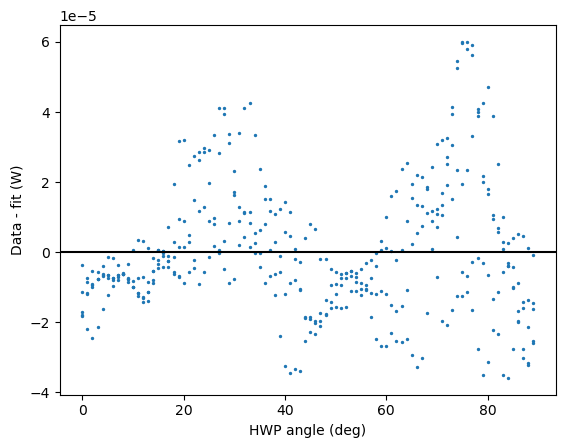

In [30]:
phase = np.mod(hwp_ang, 90)
residual = power - power_function(hwp_ang, *paras)

print(np.sum(residual**2))

plt.figure()
plt.scatter(phase, residual, s=2)
plt.axhline(0, color="k")
plt.xlabel("HWP angle (deg)")
plt.ylabel("Data - fit (W)")